# <font color='Red'>**SMS Spam Detection System using Machine Learning and Natural Language Processing (NLP)**</font>
**Import Libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import joblib

## **Data Collection & Preprocessing**

In [2]:
from google.colab import files
uploaded = files.upload()

Saving spam.csv to spam.csv


In [3]:
data = pd.read_csv('spam.csv', encoding='latin-1')
data.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [4]:
print(f'The Dataset has {data.shape[0]} rows and {data.shape[1]} columns')

The Dataset has 5572 rows and 5 columns


In [5]:
data.columns.to_list()     # These 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4' columns are unnecessary so lets remove them

['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']

In [6]:
data = data[['v1', 'v2']]
data.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [7]:
# Rename the columns
data = data.rename(columns={'v1':'label', 'v2':'sms'})
data.head()

,label,sms
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   5572 non-null   object
 1   sms     5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [9]:
data['label'].value_counts()                # The number of spam and ham (not spam) sms

,count
label,
ham,4825
spam,747


### **Data Cleaning**

In [10]:
print('Duplicate rows in the Dataset:',data.duplicated().sum())     # Checking duplicate rows

Duplicate rows in the Dataset: 403


In [11]:
data = data.drop_duplicates().reset_index(drop=True)        # Dropping duplicate rows and resetting index

In [12]:
print('Duplicate rows in the Dataset:',data.duplicated().sum())

Duplicate rows in the Dataset: 0


In [13]:
data.isna().sum()              # Checking for any missing value

,0
label,0
sms,0


In [14]:
display(data.sample(5))    # Display 5 random rows to visualize

,label,sms
4893,ham,Gud ni8.swt drms.take care
3059,ham,Guess he wants alone time. We could just show ...
2966,ham,Thats cool. i liked your photos. You are very ...
845,ham,Dude ive been seeing a lotta corvettes lately
3583,ham,At the funeral home with Audrey and dad


In [15]:
data['label'] = data['label'].astype('string').str.strip().str.lower()      # Converting labels to lowercase and removing any whitespace
data['sms'] = data['sms'].astype('string').str.strip().str.lower()          # Converting sms to lowercase and removing any whitespace

,Counts,Percentage
label,,
ham,4516,87.0
spam,653,13.0


2

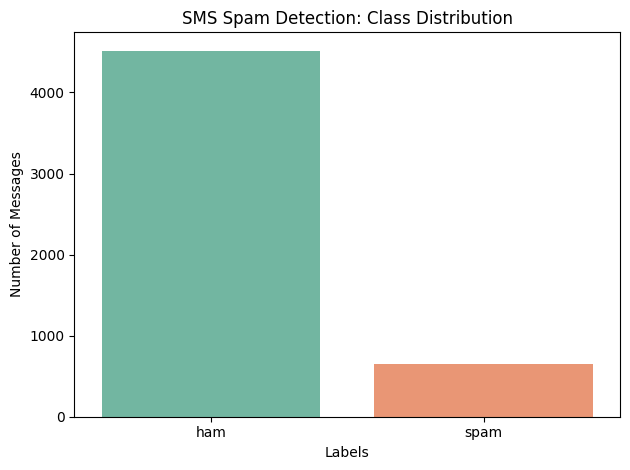

In [16]:
class_counts = data['label'].value_counts()
class_percentages = data["label"].value_counts(normalize=True).mul(100)
class_summary = pd.DataFrame({
    'Counts':class_counts,
    'Percentage':class_percentages
})
display(round(class_summary), 2)
sns.countplot(data=data, x='label', hue='label', order=['ham','spam'], palette='Set2')
plt.title('SMS Spam Detection: Class Distribution')
plt.xlabel('Labels')
plt.ylabel('Number of Messages')
plt.tight_layout()
plt.show()

## **Feature Engineering**

In [17]:
data['character_count'] = data['sms'].str.len()
data['word_count'] = data['sms'].str.split().str.len()
data['digit_count'] = data['sms'].str.count(r'\d')
data['exclamation_count'] = data['sms'].str.count('!')
data['url_indicator'] = data['sms'].str.contains(r'https?://|www\.', case=False, regex=True).astype(int)
display(data.head())

,label,sms,character_count,word_count,digit_count,exclamation_count,url_indicator
0,ham,"go until jurong point, crazy.. available only ...",111,20,0,0,0
1,ham,ok lar... joking wif u oni...,29,6,0,0,0
2,spam,free entry in 2 a wkly comp to win fa cup fina...,155,28,25,0,0
3,ham,u dun say so early hor... u c already then say...,49,11,0,0,0
4,ham,"nah i don't think he goes to usf, he lives aro...",61,13,0,0,0


**Inspecting common words in spam and legitimate messages**

In [18]:
def get_top_words(messages, top_n=15):
  vectorizer = CountVectorizer(stop_words=None, token_pattern=r'(?u)\b\w+\b')    # Creates a word counter that retains common words and single-character tokens
  word_matrix = vectorizer.fit_transform(messages)    # Converts the supplied messages into a sparse word-count matrix
  word_totals = np.asarray(word_matrix.sum(axis=0)).ravel()   # Calculates the total of each vocabulary word
  vocabulary = vectorizer.get_feature_names_out()    # Retrieves the vocabulary in the same order as the matrix columns
  word_frequency = pd.Series(word_totals, index=vocabulary)    # Associates each word with its total frequency
  return word_frequency.sort_values(ascending=False).head(top_n)   # Returns the most frequent words

spam_top_words = get_top_words(data.loc[data['label'] == 'spam', 'sms'])    # Calculates frequent words in spam messages
ham_top_words = get_top_words(data.loc[data['label'] == 'ham', 'sms'])      # Calculates frequent words in ham messages
print('Most frequent words in spam messages: ')
display(spam_top_words.to_frame(name='Frequency'))
print('\nMost frequent words in legitimate (Ham) messages:')
display(ham_top_words.to_frame(name='Frequency'))

Most frequent words in spam messages: 


,Frequency
to,596
a,332
call,309
you,268
å,247
your,242
free,195
2,184
for,184
the,183



Most frequent words in legitimate (Ham) messages:


,Frequency
i,2775
you,1875
to,1474
the,1051
a,961
u,915
and,825
in,757
me,727
my,675


In [19]:
data['label_encoded'] = data['label'].map({'ham': 0, 'spam': 1})
display(data[['sms','label','label_encoded']].head())

,sms,label,label_encoded
0,"go until jurong point, crazy.. available only ...",ham,0
1,ok lar... joking wif u oni...,ham,0
2,free entry in 2 a wkly comp to win fa cup fina...,spam,1
3,u dun say so early hor... u c already then say...,ham,0
4,"nah i don't think he goes to usf, he lives aro...",ham,0


## **Model Training**

In [20]:
x = data['sms']
y = data['label_encoded']
print('Total messages:',len(x))
print('Target shape:',y.shape)

Total messages: 5169
Target shape: (5169,)


In [21]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print('Training messages:',len(x_train),'& Training Labels:',len(y_train))
print('Testing messages:',len(x_test), '& Testing Labels:',len(y_test))

Training messages: 4135 & Training Labels: 4135
Testing messages: 1034 & Testing Labels: 1034


**Converting Messages into Bag of Words features**

- **Bag of Words:** Text representation technique that converts text into numerical vectors based on the frequency of each word, ignoring grammmar and word order

In [22]:
# Creating a Bag of Words vectorizer
bag_of_words_vectorizer = CountVectorizer(
    lowercase=True,        # Convert text to lowercase before tokenizing
    stop_words=None,       # Keeping all words
    ngram_range=(1, 1),    # Using individual words rather than word pairs
    min_df=2               # Keeping terms appearing in at least two training messages
)

# Learn the vocabulary from training messages and convert them to word-count features
x_train_bow = bag_of_words_vectorizer.fit_transform(x_train)
# Tansform test messages using learned training vocabulary only
x_test_bow = bag_of_words_vectorizer.transform(x_test)

print('Bag of words training shape: ',x_train_bow.shape)
print('Bag of words testing shape: ',x_test_bow.shape)
print('\nSample Bag of words vocabulary: ',bag_of_words_vectorizer.get_feature_names_out()[:20])

Bag of words training shape:  (4135, 3288)
Bag of words testing shape:  (1034, 3288)

Sample Bag of words vocabulary:  ['00' '000' '02' '0207' '03' '04' '05' '050703' '0578' '06' '07'
 '0776xxxxxxx' '07xxxxxxxxx' '08' '0800' '08000776320' '08000839402'
 '08000930705' '08000938767' '08001950382']


**Converting messages into TF-IDF Features**

- **TF-IDF (Term-Frequency-Inverse Document Frequency)**: A text representation technique that assigns a weight to each word based on how frequently it appears in a document and rare it is across all documents.

(More weight to frequently occurring words and less weight to less occurring words across all documents)  


In [23]:
tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words=None,
    ngram_range=(1, 2),    # Using both single words and two-word phrases unlike 'bag of words vectorizer'
    min_df=2,              # keeping terms appearing in atleast two training messages
    sublinear_tf=True      # Applying logarthmic scaling to term frequency
)

# Learing TF-IDF vocabulary and weights from training messages
x_train_tfidf = tfidf_vectorizer.fit_transform(x_train)
# Transfrom test messages using learned training vocabulary and weights
x_test_tfidf = tfidf_vectorizer.transform(x_test)

print('TF-IDF training shape:',x_train_tfidf.shape)
print('TF-IDF testing shape:',x_test_tfidf.shape)
print('\nSample TF-IDF vocabulary:',tfidf_vectorizer.get_feature_names_out()[:20])

TF-IDF training shape: (4135, 10033)
TF-IDF testing shape: (1034, 10033)

Sample TF-IDF vocabulary: ['00' '00 per' '00 sub' '000' '000 bonus' '000 cash' '000 prize'
 '000 xmas' '02' '02 06' '02 09' '0207' '0207 153' '03' '03 05' '03 this'
 '04' '05' '050703' '050703 csbcm4235wc1n3xx']


In [24]:
# Checking that the lengths of training and testing features match thier respective target counts for both BoW and TF-IDF vectorizers
print(x_train_bow.shape[0] == len(y_train))
print(x_test_bow.shape[0] == len(y_test))
print(x_train_tfidf.shape[0] == len(y_train))
print(x_test_tfidf.shape[0] == len(y_test))

True
True
True
True


## **Model Building**
**Multinomial Naive Bayes + Bag of Word**

In [25]:
nb_bow_model = MultinomialNB()
print('Model 1 trained: Multinomial Naive bayes + Bag of Words\n')
nb_bow_model.fit(x_train_bow, y_train)   # Training naive bayes model with bag of words features and training label

Model 1 trained: Multinomial Naive bayes + Bag of Words



MultinomialNB()

**Multinomial Naive Bayes + TF-IDF**

In [26]:
nb_tfidf_model = MultinomialNB()
print('Model 2 trained: Multinomial Naive Bayes + TF-IDF\n')
nb_tfidf_model.fit(x_train_tfidf, y_train)      # Training naive bayes model with TF-IDF features and training labels

Model 2 trained: Multinomial Naive Bayes + TF-IDF



MultinomialNB()




**Logistic Regression + Bag of Word**

In [27]:
lr_bow_model = LogisticRegression(
    max_iter=1000,          # Allow upto 1,000 optimization iterations
    random_state=42
)
print('Model 3 trained: Logistic Regression + Bag of Words\n')
lr_bow_model.fit(x_train_bow, y_train)     # Training logistic regression with bag of words features and training labels

Model 3 trained: Logistic Regression + Bag of Words



LogisticRegression(max_iter=1000, random_state=42)

**Logistic Regression + TF-IDF**

In [28]:
lr_tfidf_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
print('Model 4 trained: Logistic Regression + TF-IDF\n')
lr_tfidf_model.fit(x_train_tfidf, y_train)    # Training logistic regression with TF-IDF features and training labels

Model 4 trained: Logistic Regression + TF-IDF



LogisticRegression(max_iter=1000, random_state=42)

In [29]:
# Checking which classes the various models learned (optional)
print('Ham (0) and Spam (1) are the two classes')
print(nb_bow_model.classes_)
print(nb_tfidf_model.classes_)
print(lr_bow_model.classes_)
print(lr_tfidf_model.classes_)

Ham (0) and Spam (1) are the two classes
[0 1]
[0 1]
[0 1]
[0 1]


## **Model Evaluation**

**Generating predictions on test set**

In [30]:
# Predict (ham or spam) using Bag of Words Naive Bayes model
y_pred_nb_bow = nb_bow_model.predict(x_test_bow)

# Predict (ham or spam) using TF-IDF Naive Bayes model
y_pred_nb_tfidf = nb_tfidf_model.predict(x_test_tfidf)

# Predict (ham or spam) using Bag of Words Logistic Regression model
y_pred_lr_bow = lr_bow_model.predict(x_test_bow)

# Predict (ham or spam) using TF-IDF Logistic Regression model
y_pred_lr_tfidf = lr_tfidf_model.predict(x_test_tfidf)

print('Test-set predictions generated for all four models')

Test-set predictions generated for all four models


**For this project we treat spam (1) as the positive class.**
- **Precision**: Of all the messages predicted as spam, how many were actually spam?
- **Recall**: Of all spam messages, how many did the model detected?
- **F1-Score**: Combines Precision and Recall into one score
- **Accuracy**: The Proportion of all messages classified correctly

In [31]:
model_predictions = {
    'Naive Bayes + BoW': y_pred_nb_bow,
    'Naive Bayes + TF-IDF': y_pred_nb_tfidf,
    'Logistic-Regression + BoW': y_pred_lr_bow,
    'Logistic-Regression + TF-IDF': y_pred_lr_tfidf
}
evaluation_results = []

for model_name, y_pred in model_predictions.items():
  accuracy = accuracy_score(y_test, y_pred)
  precision = precision_score(y_test, y_pred, pos_label=1, zero_division=0)   # Calculating Precision for spam class (label 1)
  recall = recall_score(y_test, y_pred, pos_label=1, zero_division=0)         # Calculating Recall for spam class (label 1)
  f1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)                 # Calculating F1-score for spam class (label 1)
  evaluation_results.append({
      'Model': model_name,
      'Accuracy': accuracy,
      'Precision': precision,
      'Recall': recall,
      'F1-Score': f1
  })
results_df = pd.DataFrame(evaluation_results)
results_df = results_df.sort_values(by='F1-Score', ascending=False).reset_index(drop=True)    # Sorting based on highest F1-Score
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Naive Bayes + BoW,0.9855,0.9677,0.9160,0.9412
1,Logistic-Regression + BoW,0.9807,0.9912,0.8550,0.9180
2,Naive Bayes + TF-IDF,0.9623,1.0000,0.7023,0.8251
3,Logistic-Regression + TF-IDF,0.9613,0.9892,0.7023,0.8214


In [32]:
for model_name, y_pred in model_predictions.items():
  print(f'\n{'=' * 60}\n{model_name}\n{'=' * 60}')
  print(
      classification_report(
          y_test,      # Actual test labels
          y_pred,      # Predicted test labels
          labels=[0, 1],    # Explicitly specify ham and spam classes
          target_names=['Ham', 'Spam'],
          digits=4,            # Display four decimal places
          zero_division=0      # Avoid division warnings for undefined scores
      )
  )


Naive Bayes + BoW
              precision    recall  f1-score   support

         Ham     0.9879    0.9956    0.9917       903
        Spam     0.9677    0.9160    0.9412       131

    accuracy                         0.9855      1034
   macro avg     0.9778    0.9558    0.9665      1034
weighted avg     0.9854    0.9855    0.9853      1034


Naive Bayes + TF-IDF
              precision    recall  f1-score   support

         Ham     0.9586    1.0000    0.9789       903
        Spam     1.0000    0.7023    0.8251       131

    accuracy                         0.9623      1034
   macro avg     0.9793    0.8511    0.9020      1034
weighted avg     0.9638    0.9623    0.9594      1034


Logistic-Regression + BoW
              precision    recall  f1-score   support

         Ham     0.9794    0.9989    0.9890       903
        Spam     0.9912    0.8550    0.9180       131

    accuracy                         0.9807      1034
   macro avg     0.9853    0.9269    0.9535      1034
weight

**Confusion matrix guide:**
- **True Positive:** Model correctly predicts the Positive class. (spam is the positive class in our case)
- **True Negative:** The model corectly predicts the Negative class. (ham is the negative class in our case)
- **False Positive:** The model predicts positive but the actual class is Negative. (Model predicts 'Spam' but it actually is 'Ham')
- **False Negative:** The model predicts Negative but the actual class is Positive.(Spam was incorrectly flagged as Ham)


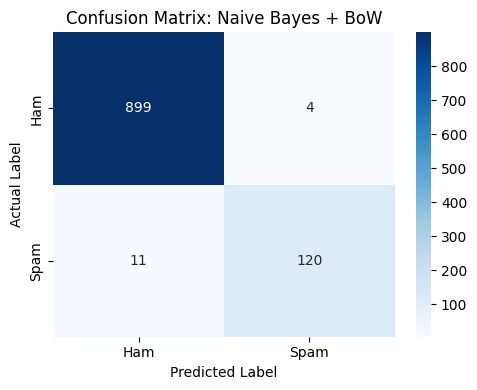

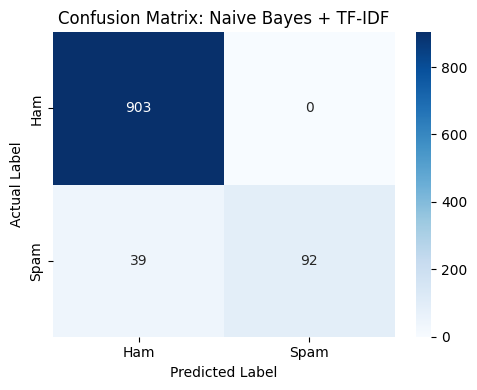

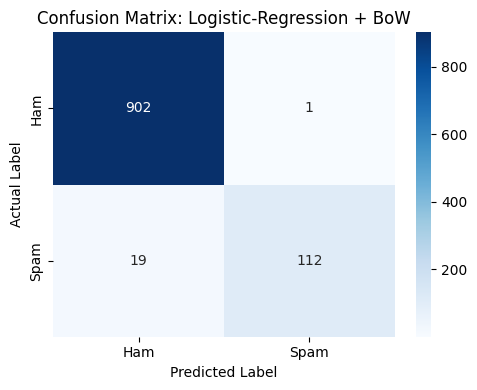

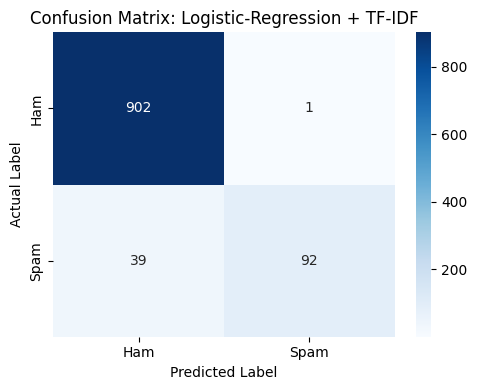

In [33]:
for model_name, y_pred in model_predictions.items():
  cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
  plt.figure(figsize=(5, 4))
  sns.heatmap(
      cm,
      annot=True,
      fmt='d',      # Displays values in integer whole numbers
      cmap='Blues',
      xticklabels=['Ham', 'Spam'],
      yticklabels=['Ham', 'Spam']
  )
  plt.title(f'Confusion Matrix: {model_name}')
  plt.xlabel('Predicted Label')
  plt.ylabel('Actual Label')
  plt.tight_layout()
  plt.show()

**Error Analysis**

In [34]:
# Inspect misclassified messages
best_model_name = results_df.iloc[0]['Model']
best_predictions = model_predictions[best_model_name]
error_analysis = pd.DataFrame({
    'sms':x_test,
    'actual':y_test,
    'predicted':best_predictions
})
error_analysis['actual'] = error_analysis['actual'].map({0 : 'ham', 1 : 'spam'})
error_analysis['predicted'] = error_analysis['predicted'].map({0 : 'ham', 1 : 'spam'})
misclassified = error_analysis[
    error_analysis['actual'] != error_analysis['predicted']
    ].copy()
print('Model inspected:',best_model_name)
print('Misclassified messages:', len(misclassified))
display(misclassified)

Model inspected: Naive Bayes + BoW
Misclassified messages: 15


,sms,actual,predicted
1610,hi if ur lookin 4 saucy daytime fun wiv busty ...,spam,ham
1422,hi its lucy hubby at meetins all day fri & i w...,spam,ham
3947,missed call alert. these numbers called but le...,spam,ham
4806,k k:) sms chat with me.,ham,spam
660,sms. ac sun0819 posts hello:\you seem cool,spam,ham
2302,babe: u want me dont u baby! im nasty and have...,spam,ham
2179,88066 from 88066 lost 3pound help,spam,ham
3888,in the simpsons movie released in july 2007 na...,spam,ham
3330,xmas & new years eve tickets are now on sale f...,spam,ham
5062,"latest news! police station toilet stolen, cop...",spam,ham


## **Prediction Function**

In [35]:
model_config = {
    'Naive Bayes + BoW':(bag_of_words_vectorizer, nb_bow_model),
    'Naive Bayes + TF-IDF':(tfidf_vectorizer, nb_tfidf_model),
    'Logistic Regression + BoW':(bag_of_words_vectorizer, lr_bow_model),
    'Logistic Regression + TF_IDF':(tfidf_vectorizer, lr_tfidf_model)
}
best_vectorizer, best_model = model_config[best_model_name]

def predict_sms(message):
  if not isinstance(message, str):
    raise TypeError('Message must be a string')
  if not message.strip():
    raise ValueError('Message cannot be empty')

  message_features = best_vectorizer.transform([message])   # Converting message into Bag of Words
  prediction = int(best_model.predict(message_features)[0])            # Predicts numeric class (0 ham and 1 spam)
  probabilities = best_model.predict_proba(message_features)[0]   # Retrives models estimated probabilities for both class
  spam_index = list(best_model.classes_).index(1)
  predicted_label = 'Spam' if prediction == 1 else 'Ham'
  return {
      'message':message,
      'prediction':predicted_label,
      'spam_probability': float(probabilities[spam_index])
  }

**Testing the Prediction Function**

In [36]:
sample_messages = [
    "Hey, are we still meeting at 6 pm?",
    "Congratulations! You have won a free prize. Click here now!",
    "Please call me when you reach home.",
    "URGENT! Claim your cash reward today by clicking this link."
]
for message in sample_messages:
  result = predict_sms(message)
  print('Message:',result['message'])
  print('Prediction:',result['prediction'])
  print(f'Spam Probability: {result['spam_probability']:.2%}')
  print('-' * 60)

Message: Hey, are we still meeting at 6 pm?
Prediction: Ham
Spam Probability: 0.00%
------------------------------------------------------------
Message: Congratulations! You have won a free prize. Click here now!
Prediction: Spam
Spam Probability: 100.00%
------------------------------------------------------------
Message: Please call me when you reach home.
Prediction: Ham
Spam Probability: 0.09%
------------------------------------------------------------
Message: URGENT! Claim your cash reward today by clicking this link.
Prediction: Spam
Spam Probability: 100.00%
------------------------------------------------------------


## **User-friendly input**
**(Enter your SMS to get prediction)**

<font color="green">**`Re-Run the below cell to enter another SMS`**</font>

In [37]:
new_message = input('Enter an SMS message: ')
result = predict_sms(new_message)
print('Model used: ',best_model_name)
print('Predictions:',result['prediction'])
print(f'Spam Probability: {result['spam_probability']:.2%}')

Enter an SMS message: Hi this is free please enroll!!!
Model used:  Naive Bayes + BoW
Predictions: Spam
Spam Probability: 61.03%


In [38]:
# Saving the Best Model and Vectorizer for Model Deployment
joblib.dump(
    (best_model, best_vectorizer),
    'sms_spam_model.pkl'
)

# Download the saved model to your computer.
files.download('sms_spam_model.pkl')
print('Model saved successfully!!!')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model saved successfully!!!



# **Project Summary**

This project builds an **SMS Spam Detection System using Machine Learning and Natural Language Processing (NLP)** to classify text messages as either legitimate messages (Ham) or unwanted messages (Spam). It explores text data, extracts word-based features using Bag of Words and TF-IDF, trains multiple classification models, and selects the best-performing model for predicting new SMS messages.

## **Dataset Overview**

The dataset, `spam.csv`, contains **5,572 rows and 5 columns** initially. The columns `v1` and `v2` are renamed to `label` and `sms` for clarity.

- **Ham:** Legitimate messages.
- **Spam:** Unwanted or promotional messages.
- Duplicate rows are removed, and the index is reset.

Additional features are explored, including character count, word count, digit count, exclamation mark count, and URL indicators. The most frequent words in spam and ham messages are also analyzed.

## **Project Workflow**

### **1. Data Preparation**

The target labels are encoded numerically:

- `0` — Ham
- `1` — Spam


### **2. Text Feature Extraction**

Two text representation techniques are used:

- **Bag of Words (BoW):** Converts messages into word-count features using individual words.
- **TF-IDF:** Converts messages into weighted text features using individual words and two-word phrases.


### **3. Model Training**

Four machine learning models are trained and evaluated:

1. Multinomial Naive Bayes + Bag of Words
2. Multinomial Naive Bayes + TF-IDF
3. Logistic Regression + Bag of Words
4. Logistic Regression + TF-IDF

The models are evaluated using accuracy, precision, recall, and F1-score, with particular attention to performance on the Spam class.

## **Model Performance**

The **Multinomial Naive Bayes + Bag of Words** model achieves the highest F1-score for the Spam class among the four tested models.

| Metric | Naive Bayes + BoW |
|---|---:|
| Accuracy | 98.55% |
| Spam Precision | 96.77% |
| Spam Recall | 91.60% |
| Spam F1-Score | 94.12% |

The model correctly classifies most legitimate and spam messages. Its confusion matrix is used to examine classification performance, while error analysis identifies **15 misclassified messages** in the test set.

## **SMS Prediction System**

A custom `predict_sms()` function allows users to enter a new SMS message and receive:

- Predicted class: **Ham** or **Spam**
- Estimated spam probability

The selected model is used to classify sample messages and user-provided SMS text.

## **Conclusion**

This project demonstrates how **Natural Language Processing and machine learning** can be combined to detect SMS spam. By comparing Bag of Words and TF-IDF with Multinomial Naive Bayes and Logistic Regression, the project identifies Naive Bayes with Bag of Words as the best-performing configuration for this test set.

<font color='green'><b>The selected model achieves **98.55% accuracy** and a **94.12% Spam F1-score**, making it a strong baseline for SMS spam classification</font>

